# Power Length V5

This takes a phase diagram - varies cavity length and power, and takes spectral readings, images and output power at each point. 

### Imports

In [1]:
%load_ext autoreload
%autoreload 2

import time
import logging
import winsound
import numpy as np
from tqdm.notebook import tqdm
import Components as comp
from Measure import power_scan
import socket
import sys
if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")


from pbec_analysis import make_timestamp

D:\Experiments\Semiconductor Cavity\Pbec_Experimental_Code\Measure.py:8: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


### Initialise Equipment
If equipment can take measurements, can set measure = True or False when initialising them. Note some components are interdependent.

In [4]:
components = dict()

components.update({"laser": comp.Toptica_Laser(com_port='COM5')})
components.update({"powermeter": comp.Thor_PowerMeter(power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR', num_power_readings=100, bs_factor=1, wavelength=950)})
# components.update({"spectrometer": comp.Spectrometer(spec_nd=1 / 30.5, total_time=100, initial_time=1000, min_lamb=910)})
# components.update({"camera": comp.FLIR_Camera(measure=True, )})
# .update({"wheel": comp.FilterWheel(com_port='COM9', allowed_filter_positions = [0, 5])})



TopticaBackendError: backend exception: SerialException("could not open port 'COM5': PermissionError(13, 'Access is denied.', None, 5)") ('could not open port 'COM5': PermissionError(13, 'Access is denied.', None, 5)')

### Choose loop parameters

In [3]:
# components['laser'].set(248e-3)

In [3]:

#Define PCA range
length_list = np.linspace(8, -1, 7)
stage_list = np.linspace(0, 4e6, 8, dtype=int)
stage_list = stage_list + 0.0
#Define power range
power_list = np.linspace(8e-3, 15e-3, 50)


type(stage_list[0])

numpy.float64

### Measurement Loop
Note Kinesis stage needs to be closed each time it is used, or won't be able to open again - so only use the stage using 'with' statements. 

In [ ]:
# %qtconsole

time_stamps = []
logging.basicConfig(filename = fr'Logs\power_lengthV5_{make_timestamp()}.log', filemode='w', level=logging.INFO, force=True)
print('hi')
with comp.Translation_Stage(26000913, is_rack_system = False, scale = 1) as stage, comp.FLIR_Camera(measure=True, algorithm='rising') as camera:
    components.update({"camera": camera})
    pbar = tqdm(stage_list)
    for s in pbar:
        stage.set(s)
        pbar.set_description(f'Test Displacement {s}')
        time.sleep(1)
    
    for s in tqdm(stage_list):
        stage.set(s)
        time.sleep(1)
        comp.params.update({"stage_pos": s})
        
        #Slowly return to initial wavelength
        for l in np.flip(length_list):
            comp.set_lock(l)
            time.sleep(5)
        
        for l in tqdm(length_list, leave=True):
            comp.set_lock(l) #save pca value
            ts = power_scan(power_list, components, l)
            time_stamps.append(ts)
    stage.set(0)
    components['laser'].set(0)
print("'"+str(time_stamps[0][0])+"'"+","+"'"+str(time_stamps[-1][-1])+"'")
winsound.Beep(1000, 2000)



In [5]:
np.append(np.append(np.arange(0,7,0.5),np.arange(7, 12,0.2)),np.arange(12, 60, 2))/1000


array([0.    , 0.0005, 0.001 , 0.0015, 0.002 , 0.0025, 0.003 , 0.0035,
       0.004 , 0.0045, 0.005 , 0.0055, 0.006 , 0.0065, 0.007 , 0.0072,
       0.0074, 0.0076, 0.0078, 0.008 , 0.0082, 0.0084, 0.0086, 0.0088,
       0.009 , 0.0092, 0.0094, 0.0096, 0.0098, 0.01  , 0.0102, 0.0104,
       0.0106, 0.0108, 0.011 , 0.0112, 0.0114, 0.0116, 0.0118, 0.012 ,
       0.014 , 0.016 , 0.018 , 0.02  , 0.022 , 0.024 , 0.026 , 0.028 ,
       0.03  , 0.032 , 0.034 , 0.036 , 0.038 , 0.04  , 0.042 , 0.044 ,
       0.046 , 0.048 , 0.05  , 0.052 , 0.054 , 0.056 , 0.058 ])

Power is : 0.0
Power is : 0.25
Power is : 0.5
Power is : 0.75
Power is : 1.0
Power is : 1.25
Power is : 1.5
Power is : 1.75
Power is : 2.0
Power is : 2.25
Power is : 2.5
Power is : 2.75
Power is : 3.0
Power is : 3.25
Power is : 3.5
Power is : 3.75
Power is : 4.0
Power is : 4.25
Power is : 4.5
Power is : 4.75
Power is : 5.0
Power is : 5.25
Power is : 5.5
Power is : 5.75
Power is : 6.0
Power is : 6.25
Power is : 6.5
Power is : 6.75
Power is : 7.0
Power is : 7.25
Power is : 7.5
Power is : 7.75
Power is : 8.0
Power is : 8.25
Power is : 8.5
Power is : 8.75
Power is : 9.0
Power is : 9.25
Power is : 9.5
Power is : 9.75
Power is : 10.0
Power is : 10.25
Power is : 10.5
Power is : 10.75
Power is : 11.0
Power is : 11.25
Power is : 11.5
Power is : 11.75
Power is : 12.0
Power is : 12.25
Power is : 12.5
Power is : 12.75
Power is : 13.0
Power is : 13.25
Power is : 13.5
Power is : 13.75
Power is : 14.0
Power is : 14.25
Power is : 14.5
Power is : 14.75
Power is : 15.0
Power is : 15.25
Power is : 15.5
P

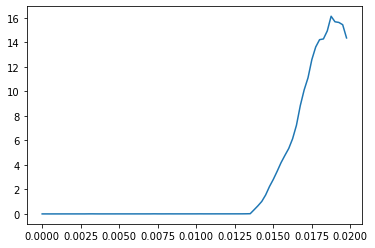

In [10]:
power_output_list =[]
#power_list = np.append([0],np.linspace(8e-3, 20e-3, 25))
#power_list = np.append([0],np.linspace(12e-3, 14e-3, 21))
#power_list = np.append(np.append(np.arange(0,7,0.5),np.arange(7, 12,0.2)),np.arange(12, 72, 2))/1000
power_list = np.arange(0,20,0.25)/1000

for x in power_list:
    print('Power is :',x*1000)
    components['laser'].set(x)
    power_reading = []
    for k in range(1):
        power_reading.append(10**6*components['powermeter'].take_power_reading())
    power_output_list.append(np.mean(np.array(power_reading)))


print(power_list)    
print(power_output_list)
components['laser'].set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)


In [7]:
components['laser'].set(0.020)

(5.94855274823,
 3.90919068896,
 2.74270539629,
 4.261045343079999,
 4.09445803778,
 6.421831075230001,
 6.743799589339998,
 7.656909975929999,
 7.402762942370001,
 5.52842341469,
 6.86234722021,
 7.5956377562499995,
 8.22903065593,
 7.9896196657699985,
 8.260521427030001,
 8.19110652577,
 8.06272428682,
 7.988422460539999,
 7.979063167550001,
 7.8532509587699995,
 8.69269691883,
 10.756818045220001,
 14.2499533913,
 18.181332132900003,
 22.0516387424,
 25.8612622402,
 30.9493619826,
 39.308358177100004,
 40.6814216536,
 41.619201663,
 58.296297294,
 67.11459092209999,
 69.7153911177,
 77.35527682649999,
 77.76443128740001,
 85.82619968709999,
 96.0804403921,
 99.36049412779998,
 72.75495852770001,
 63.6242108142,
 70.11458564910001,
 74.77686015270001,
 71.4142284023,
 73.5948221332,
 69.40451505529998,
 60.69051311590001,
 64.5989297112,
 61.561098731,
 59.34868876749999,
 57.0126009543,
 53.096974003899994)

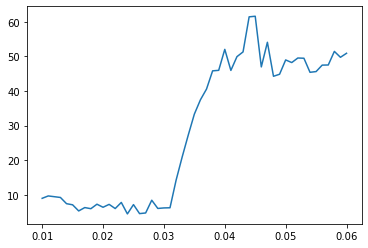

In [7]:
components['laser'].set(0.020)

power_list = np.arange(10,61,1)/1000
output = [8.96627103898, 9.65494243822, 9.4374201221, 9.21353071482, 7.41880514734, 7.091749266939999, 5.319168073560001, 6.291849107420001, 5.96844562632, 7.26224302072, 6.380671326700001, 7.21940624828, 6.010599996080001, 7.777208936719999, 4.45759992192, 7.14735344538, 4.5440751007, 4.73220764958, 8.41617664676, 6.03752053434, 6.1884854132000005, 6.234318978360001, 14.19494910712, 20.9192442962, 27.262032569000002, 33.31034781140001, 37.4552681188, 40.557917905, 45.817467450600006, 45.97208002079999, 52.0308062114, 45.9457144802, 49.9252053868, 51.295995893, 61.434517643400014, 61.6065591156, 46.9607277052, 54.0777357164, 44.2504454682, 44.836113483199995, 48.9749715212, 48.2168066738, 49.532669807, 49.46344671559999, 45.3978791036, 45.6108798896, 47.475886350799996, 47.515162702599994, 51.440807925399994, 49.74002462279999, 50.89879371319999]
plt.plot(power_list, output)
[1.1451708054999998, 1.1436845179, 1.1431032859999999, 1.1439897534999999, 1.1470676919, 1.1468337447, 1.1466527904, 1.1473144459000002, 1.1456968742, 1.1446185057000002, 1.1411494065, 1.1433427286, 1.14585588, 1.1478499758999998, 1.1475319536, 1.1466253690000001, 1.1461355404, 1.1468812546999998, 1.1433902607, 1.1426682897999998, 1.1432001632, 1.1458376181999999, 1.1493999132000001, 1.1505824764, 1.1499482390999998, 1.1536256968, 1.1625140774, 2.326687695, 3.7798772906999996, 5.584403897899998, 7.3027481173, 9.216044800599999, 11.783908769999998, 13.240469133, 15.260647289000001, 18.019721561, 21.238687006, 26.151887267, 37.106839695000005, 38.20940974, 33.133502578000005, 62.001342415, 69.05317466400001, 80.00219357000002, 80.275702277, 94.979206548, 96.456435766, 92.494653667, 97.30012750499999, 107.042850115, 103.666819831, 119.77026217000001, 141.57916495999999, 138.94238059999998, 134.75723080999995, 141.66007643999998, 131.349522977, 137.433114625, 173.0225463, 92.25698538700001, 104.903846736]

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.optimize import curve_fit

spin = np.array(Image.open(r"D:\Data\2025\202501\20250113\Spinview spot size 18.png"))
thor = np.array(Image.open(r"D:\Data\2025\202501\20250113\Thorcam spotsizev 18.png"))

if len(spin.shape) == 3:
    spin = np.mean(spin, axis=2)
if len(thor.shape) == 3:
    thor = np.mean(thor, axis=2)

spin_threshold = spin > np.max(spin) * 0.1  # Adjust threshold based on the intensity range


spin_profile = np.sum(spin_threshold, axis=1)  # Summing along the vertical axis (y-axis)


def gaussian(x, amplitude, mean, sigma, offset):
    return amplitude * np.exp(-(x - mean)**2 / (2 * sigma**2)) + offset

def fit_gaussian(profile):
    x_data = np.arange(len(profile))
    p0 = [np.max(profile), len(profile) // 2, 10, np.min(profile)]
    params, _ = curve_fit(gaussian, x_data, profile, p0=p0)
    amplitude, mean, sigma, offset = params
    radius = sigma * np.sqrt(2 * np.log(1 / np.exp(2)))
    return radius, params

# Ensure both profiles have the same length


# Now proceed with the rest of the code as before
spin_radius, spin_params = fit_gaussian(spin_profile)


x_data = np.arange(len(spin(profile)))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(x_data, spin_profile, label="Spinview Intensity Profile")
plt.plot(x_data, gaussian(x_data, *spin_params), label="Gaussian Fit", linestyle='--')
plt.title(f"Spinview Laser Spot Size\n1/e^2 Radius: {spin_radius:.2f} pixels")
plt.xlabel("Pixel Position")
plt.ylabel("Intensity")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x_data, thor_profile, label="Thorcam Intensity Profile")
plt.plot(x_data, gaussian(x_data, *thor_params), label="Gaussian Fit", linestyle='--')
plt.title(f"Thorcam Laser Spot Size\n1/e^2 Radius: {thor_radius:.2f} pixels")
plt.xlabel("Pixel Position")
plt.ylabel("Intensity")
plt.legend()

plt.tight_layout()
plt.show()

print(f"Spinview 1/e^2 radius: {spin_radius:.2f} pixels")
print(f"Thorcam 1/e^2 radius: {thor_radius:.2f} pixels")





<ipython-input-6-181c0819cf46>:28: RuntimeWarning: invalid value encountered in sqrt
  radius = sigma * np.sqrt(2 * np.log(1 / np.exp(2)))


NameError: name 'profile' is not defined

In [4]:
np.linspace(8e-3, 11.5e-3, 8)

array([0.008 , 0.0085, 0.009 , 0.0095, 0.01  , 0.0105, 0.011 , 0.0115])

Filter position set to: 0 for power 0.0
Filter position set to: 0 for power 0.5
Filter position set to: 0 for power 1.0
Filter position set to: 0 for power 1.5
Filter position set to: 0 for power 2.0
Filter position set to: 0 for power 2.5
Filter position set to: 0 for power 3.0
Filter position set to: 0 for power 3.5
Filter position set to: 0 for power 4.0
Filter position set to: 0 for power 4.5
Filter position set to: 0 for power 5.0
Filter position set to: 0 for power 5.5
Filter position set to: 0 for power 6.0
Filter position set to: 0 for power 6.5
Filter position set to: 0 for power 7.0
Filter position set to: 0 for power 7.5
Filter position set to: 0 for power 8.0
Filter position set to: 0 for power 8.5
Filter position set to: 0 for power 9.0
Filter position set to: 0 for power 9.5
Filter position set to: 0 for power 10.0
Filter position set to: 0 for power 10.1
Filter position set to: 0 for power 10.2
Filter position set to: 0 for power 10.299999999999999
Filter position set to

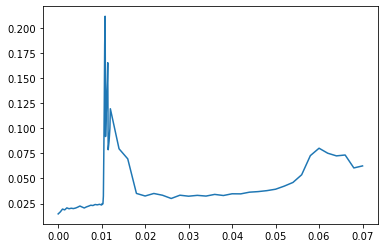

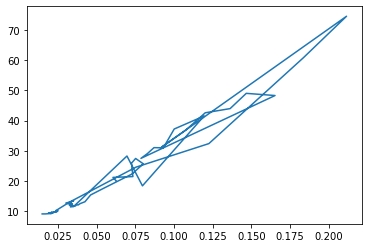

In [1]:
import matplotlib.pyplot as plt
import os
import numpy as np
from datetime import datetime
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok
from ctypes import c_int16, c_int32, byref, c_char_p,c_float

#chrome-extension://efaidnbmnnnibpcajpcglclefindmkaj/https://www.picotech.com/download/manuals/picoscope-6000-series-programmers-guide.pdf

%load_ext autoreload
%autoreload 2

import Components as comp
import socket
import sys

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

components = dict()

#filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
#laser = comp.Toptica_Laser()
components.update({"powermeter": comp.Thor_PowerMeter(power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR', num_power_readings=100, bs_factor=1, wavelength=950)})

def save_arrays(channel_data, time_array, stage_position, laser_power, base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')
    # Define the folder path following the structure Year/YearMonth/YearMonthDay
    folder_path = os.path.join(base_directory, year, year_month, year_month_day)
    # Create the directory structure if it doesn't exist
    os.makedirs(folder_path, exist_ok=True)
    # Create timestamp for file naming
    timestamp = datetime.now().strftime('%H%M%S')  # Using HHMMSS format for timestamp
    # Save each channel's data with a distinctive file name
    for channel, voltage_array in channel_data.items():
        # Generate filename for the channel data
        filename_voltage = f"pbec_{timestamp}_{stage_position}_{laser_power}_channel{channel}.txt"
        # Define full path
        array_path_voltage = os.path.join(folder_path, filename_voltage)
        # Save voltage data for this channel
        np.savetxt(array_path_voltage, voltage_array, fmt='%0.4f')
    # Save the time array with a distinctive name
    filename_time = f"pbec_{timestamp}_{stage_position}_{laser_power}_Time.txt"
    time_path = os.path.join(folder_path, filename_time)
    np.savetxt(time_path, time_array, fmt='%0.4f')


def get_picoscope_data(
        channels=[0],  # List of channels to acquire from, e.g., [0, 1] for channels A and B
        analogue_offset=0,
        trig=0,
        trigsource=0,
        trigthresh=64,
        trigdir=2,
        trigdelay=0,
        trigms=1000,
        preTriggerSamples=2500,
        postTriggerSamples=2500,
        timebase=8,
        live_plot=False
):
    # Initialize PicoScope
    status = {}
    chandle = c_int16()
    serial = c_char_p()  # Leave serial empty for single device
    status["openunit"] = ps.ps6000OpenUnit(byref(chandle), serial)
    assert status["openunit"] == 0, f"Failed to open PicoScope 6407, error code: {status['openunit']}"
    # Channel configuration mapping
    channel_mapping = {
        0: 'PS6000_CHANNEL_A',
        1: 'PS6000_CHANNEL_B',
        2: 'PS6000_CHANNEL_C',
        3: 'PS6000_CHANNEL_D'
    }
    # Enable and configure each specified channel
    buffers = {}
    chARange = ps.PS6000_RANGE['PS6000_100MV']  # ±100 mV range, the only range available for PicoScope 6407
    for ch in channels:
        if ch not in channel_mapping:
            raise ValueError("Invalid channel number. Must be 0, 1, 2, or 3.")
        channel = ps.PS6000_CHANNEL[channel_mapping[ch]]
        enabled = 1  # 1 for enabling
        coupling_type = ps.PS6000_COUPLING['PS6000_DC_50R']  # Only DC 50Ω coupling for PicoScope 6407
        bandwidth = ps.PS6000_BANDWIDTH_LIMITER['PS6000_BW_FULL']  # Full bandwidth
        # Set channel
        status[f"set_channel_{ch}"] = ps.ps6000SetChannel(
            chandle, channel, enabled, coupling_type, chARange, analogue_offset, bandwidth
        )
        assert status[f"set_channel_{ch}"] == 0, f"Error in setting channel {ch}: {status[f'set_channel_{ch}']}"
        # Create buffers for data collection on each channel
        buffers[ch] = {
            'max': (c_int16 * (preTriggerSamples + postTriggerSamples))(),
            'min': (c_int16 * (preTriggerSamples + postTriggerSamples))()  # Used for downsampling
        }
        # Set data buffer location for data collection
        status[f"setDataBuffers_{ch}"] = ps.ps6000SetDataBuffers(
            chandle, channel, byref(buffers[ch]['max']), byref(buffers[ch]['min']), preTriggerSamples + postTriggerSamples, 0
        )
        assert_pico_ok(status[f"setDataBuffers_{ch}"])
    # Trigger setup
    status["trigger"] = ps.ps6000SetSimpleTrigger(
        chandle, trig, trigsource, trigthresh, trigdir, trigdelay, trigms
    )
    assert_pico_ok(status["trigger"])
    # Set number of pre and post trigger samples
    maxSamples = preTriggerSamples + postTriggerSamples
    # Get timebase information
    timeIntervalns = c_float()
    returnedMaxSamples = c_int32()
    status["getTimebase2"] = ps.ps6000GetTimebase2(
        chandle, timebase, maxSamples, byref(timeIntervalns), 1, byref(returnedMaxSamples), 0
    )
    assert_pico_ok(status["getTimebase2"])
    # Run block capture
    status["runBlock"] = ps.ps6000RunBlock(
        chandle, preTriggerSamples, postTriggerSamples, timebase, 0, None, 0, None, None
    )
    assert_pico_ok(status["runBlock"])
    # Wait for data collection to complete
    ready = c_int16(0)
    while ready.value == 0:
        status["isReady"] = ps.ps6000IsReady(chandle, byref(ready))
    # Retrieve data from scope to buffers for each channel
    overflow = c_int16()
    cmaxSamples = c_int32(maxSamples)
    status["getValues"] = ps.ps6000GetValues(
        chandle, 0, byref(cmaxSamples), 1, 0, 0, byref(overflow)
    )
    assert_pico_ok(status["getValues"])
    # Find maximum ADC count value
    maxADC = c_int16(32512)
    # Convert data from each channel buffer to mV and store in a dictionary
    channel_data = {}
    for ch in channels:
        adc2mV_buffer = adc2mV(buffers[ch]['max'], chARange, maxADC)
        channel_data[ch] = adc2mV_buffer
    time = np.linspace(0, (cmaxSamples.value - 1) * timeIntervalns.value, cmaxSamples.value) # Create time data
    # Plot data from each channel if live_plot is enabled
    if live_plot:
        plt.figure(figsize=(5,5))
        for ch in channels:
            plt.plot(time, channel_data[ch][:], label=f"Channel {channel_mapping[ch]}")
        plt.xlabel('Time (ns)')
        plt.ylabel('Voltage (mV)')
        plt.title("PicoScope Data Capture on Multiple Channels")
        plt.legend()
        plt.grid()
        plt.show()
    # Stop the device
    status["stop"] = ps.ps6000Stop(chandle)
    assert_pico_ok(status["stop"])
    ps.ps6000CloseUnit(chandle) # Close unit (disconnect the scope)
    return channel_data, time # Return channel data and time for further processing

filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
laser = comp.Toptica_Laser()
power_pd_list = []
power_output_list =[]
#power_list = np.append([0],np.linspace(8e-3, 20e-3, 25))
#power_list = np.append([0],np.linspace(12e-3, 14e-3, 21))
power_list = np.append(np.append(np.arange(0,10,0.5),np.arange(10, 12,0.1)),np.arange(12, 72, 2))/1000
channels = [1]  # Channel A, B
time_range = 20
preSamples = 0
postSamples = 97700
plot_flag = False  # If you want to live monitor the data during the acquisition
filter_positions = [
    (0, 10.8, 1),
    (10.8, 11.400, 2),
    (11.4, 12.10, 3),
    (12.10, 13.20, 4),
    (13.2, 17.3, 5),
    (17.3, float('inf'), 6)
]
for x in power_list:
    filter_position = None
    for lower, upper, fposition in filter_positions:
        if lower <= x * 1000 < upper:
            filter_position = fposition
            break

    if filter_position is not None:
        filter_wheel.set(filter_position-1)
        print(f'Filter position set to: {filter_position-1} for power {x*1000}')
    laser.set(x)

    power_output_list.append(10**6*components['powermeter'].take_power_reading())
    a = get_picoscope_data(channels, live_plot=plot_flag, timebase=time_range,
                                           preTriggerSamples=preSamples, postTriggerSamples=postSamples)
    Voltages = a[0]
    Timing = a[1]
    power_pd_list.append(np.mean(Voltages[1]))
    save_arrays(Voltages, Timing, 0, x * 1000)

laser.set(10/1000)
print("Laser_power",power_list)
print("Powermeter_power",power_output_list)
print("Photodiode mean voltage",power_pd_list)

import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.show()

plt.plot(power_output_list, power_pd_list)
plt.show()


In [10]:
len(Voltages[1])

97700

TypeError: float() argument must be a string or a number, not 'dict'

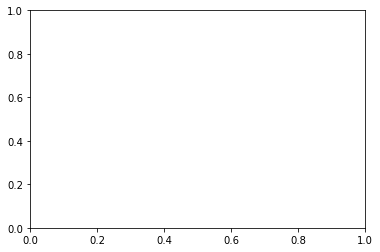

In [5]:
import matplotlib.pyplot as plt

plt.plot(Voltages)